# Self-play evaluation

Load the committed initial-model and self-play training stats, plot their loss progress, then compare each selected checkpoint with greedy play. In addition to the single-turn policies, it evaluates model play on turns 7 and 9 or turns 6 and 8 while keeping turn 10 greedy. These parity comparisons start from five-stone boards so turn 6 can be played. The original single-turn archive remains `stats/self_play_evaluation_games.npz`; the archive with both the original and parity groups is `stats/self_play_evaluation_games_with_parity.npz`. Pass the latter with `--evaluation-archive` to show the added viewer modes.

Self-play metrics describe fit on each checkpoint’s retained `X_i` training data. The initial sequential model also includes train/validation loss history and validation calibration stats. These records are saved under each run’s `stats/` folder.


In [1]:
import json
import sys
from pathlib import Path
from time import perf_counter

repo_root = Path.cwd().resolve()
while not (repo_root / 'data_generation.py').exists():
    if repo_root.parent == repo_root:
        raise RuntimeError('Could not find repository root')
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

import matplotlib.pyplot as plt
import pandas as pd
import self_play_training as self_play


In [2]:
weights_root = repo_root / 'weights' / 'self_play'
runs = {
  #  'large_m30': {'directory': weights_root / 'round9_20k', 'checkpoint': 30},
    'v5_cp12': {'directory': weights_root / 'round9_2k_v5_start6', 'checkpoint': 12},
}

# Set this to control evaluation runtime and games per policy group.
seed = 2026
num_states = 200  # 100 paired states for each model-turn group
grid_size = (10, 10, 4)
max_stones = 10


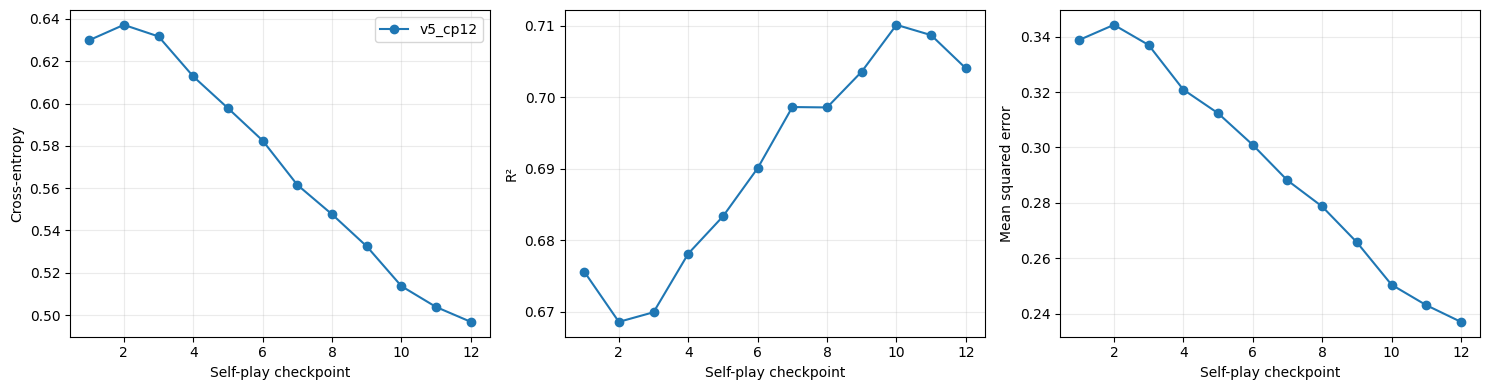

,run,checkpoint,training_rows,cross_entropy,r_squared,mse
10,v5_cp12,8,10774,0.547632,0.698587,0.278679
11,v5_cp12,9,10210,0.532496,0.703603,0.265762
1,v5_cp12,10,9675,0.513670,0.710136,0.250419
2,v5_cp12,11,9217,0.503812,0.708694,0.243038
3,v5_cp12,12,8888,0.496788,0.704051,0.236994


In [3]:
metric_rows = []
for run_name, run in runs.items():
    metrics_path = run['directory'] / 'stats' / 'training_metrics.json'
    metrics = json.loads(metrics_path.read_text())
    for checkpoint, values in metrics['checkpoints'].items():
        metric_rows.append({
            'run': run_name,
            'checkpoint': int(checkpoint),
            'training_rows': values.get('training_rows'),
            'cross_entropy': values.get('cross_entropy'),
            'r_squared': values.get('r_squared'),
            'mse': values.get('mse'),
        })
training_metrics = pd.DataFrame(metric_rows).sort_values(
    ['run', 'checkpoint']
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for metric, axis, label in zip(('cross_entropy', 'r_squared', 'mse'), axes, ('Cross-entropy', 'R²', 'Mean squared error')):
    for run_name, rows in training_metrics.groupby('run'):
        axis.plot(rows['checkpoint'], rows[metric], marker='o', label=run_name)
    axis.set_xlabel("Self-play checkpoint")
    axis.set_ylabel(label)
    axis.grid(alpha=0.25)
axes[0].legend()
fig.tight_layout()
plt.show()
training_metrics.tail()


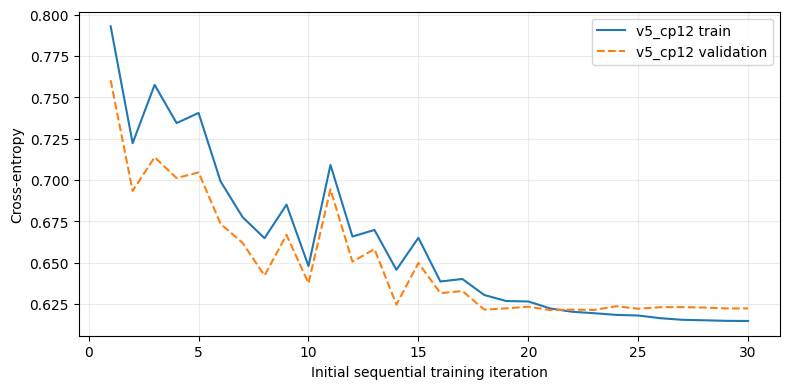

,run,checkpoint,validation_rows,final_train_cross_entropy,final_validation_cross_entropy,negative_log_probability,R²,correct_score_probability
0,v5_cp12,m_9.npz,4000,0.614687,0.622286,0.622286,0.684349,0.633591


In [4]:
initial_loss_rows = []
initial_summary_rows = []
initial_calibration_rows = []
for run_name, run in runs.items():
    run_config = json.loads((run['directory'] / 'run_config.json').read_text())
    stats_relative_path = run_config.get('initial_training_stats')
    if not stats_relative_path:
        initial_model_name = Path(run_config['initial_model']).stem
        stats_relative_path = f'stats/initial_sequential_training/{initial_model_name}_evaluation.json'
    initial_stats = json.loads((run['directory'] / stats_relative_path).read_text())
    training = initial_stats['training']
    train_loss = training['train_loss']
    validation_loss = training['validation_loss']
    for iteration, (train_value, validation_value) in enumerate(zip(train_loss, validation_loss), 1):
        initial_loss_rows.extend([
            {'run': run_name, 'iteration': iteration, 'split': 'train', 'cross_entropy': train_value},
            {'run': run_name, 'iteration': iteration, 'split': 'validation', 'cross_entropy': validation_value},
        ])
    metrics = initial_stats['stats']
    initial_summary_rows.append({
        'run': run_name,
        'checkpoint': f"m_{initial_stats['model_index']}.npz",
        'validation_rows': initial_stats['dataset_size'],
        'final_train_cross_entropy': train_loss[-1],
        'final_validation_cross_entropy': validation_loss[-1],
        'negative_log_probability': metrics['negative_log_probability']['value'],
        'R²': metrics['r_squared']['value'],
        'correct_score_probability': metrics['correct_score_probability']['value'],
    })
    for bin_stats in metrics['calibration']:
        initial_calibration_rows.append({
            'run': run_name,
            'lower_bound': bin_stats['lower_bound'],
            'upper_bound': bin_stats['upper_bound'],
            'predicted_fraction': bin_stats['predicted_fraction'],
            'predicted_stderr': bin_stats['predicted_stderr'],
            'actual_fraction': bin_stats['actual_fraction'],
            'actual_stderr': bin_stats['actual_stderr'],
            'count': bin_stats['count'],
        })

initial_training_metrics = pd.DataFrame(initial_loss_rows)
fig, axis = plt.subplots(figsize=(8, 4))
for run_name, rows in initial_training_metrics.groupby('run'):
    for split, style in (('train', '-'), ('validation', '--')):
        split_rows = rows[rows['split'] == split]
        axis.plot(split_rows['iteration'], split_rows['cross_entropy'], style, label=f'{run_name} {split}')
axis.set_xlabel('Initial sequential training iteration')
axis.set_ylabel('Cross-entropy')
axis.grid(alpha=0.25)
axis.legend()
fig.tight_layout()
plt.show()

initial_training_summary = pd.DataFrame(initial_summary_rows)
initial_training_summary


In [5]:
initial_calibration = pd.DataFrame(initial_calibration_rows)
initial_calibration


,run,lower_bound,upper_bound,predicted_fraction,predicted_stderr,actual_fraction,actual_stderr,count
0,v5_cp12,0.0,0.1,0.002527,0.000058,0.002577,0.000267,36085
1,v5_cp12,0.1,0.2,0.152255,0.000931,0.157841,0.011641,982
2,v5_cp12,0.2,0.3,0.250438,0.000821,0.251534,0.012020,1304
3,v5_cp12,0.3,0.4,0.353019,0.000692,0.363148,0.011747,1677
4,v5_cp12,0.4,0.5,0.447679,0.000980,0.478857,0.016898,875
5,v5_cp12,0.5,0.6,0.544307,0.001060,0.530556,0.018612,720
6,v5_cp12,0.6,0.7,0.646412,0.001273,0.566946,0.022687,478
7,v5_cp12,0.7,0.8,0.748165,0.001835,0.780876,0.026162,251
8,v5_cp12,0.8,0.9,0.857275,0.001887,0.859504,0.022384,242
9,v5_cp12,0.9,1.0,0.976078,0.000727,0.966089,0.004864,1386


In [6]:
checkpoint_paths = {
    run_name: run["directory"] / "checkpoints" / f"m_{run['checkpoint']}.npz"
    for run_name, run in runs.items()
}
started_at = perf_counter()
game_records = self_play.evaluate_checkpoints_against_greedy_with_games(
    checkpoint_paths=checkpoint_paths,
    num_states=num_states,
    seed=seed,
    grid_size=grid_size,
    max_stones=max_stones,
)
elapsed_seconds = perf_counter() - started_at
parity_group_names = {'model_turns_7_9', 'model_turns_6_8'}
legacy_records = [record for record in game_records if record['group'] not in parity_group_names]
legacy_results = self_play.summarize_evaluation_games(legacy_records)
greedy_results = self_play.summarize_evaluation_games(game_records)
print(f"Paired greedy evaluation completed in {elapsed_seconds:.1f} seconds")
archive_run = next(iter(runs.values()))
replay_archive_path = archive_run['directory'] / 'stats' / 'self_play_evaluation_games.npz'
parity_archive_path = archive_run['directory'] / 'stats' / 'self_play_evaluation_games_with_parity.npz'
evaluation_parameters = {
    'num_states': num_states,
    'seed': seed,
    'grid_size': grid_size,
    'max_stones': max_stones,
    'checkpoints': {name: str(path) for name, path in checkpoint_paths.items()},
}
self_play.save_evaluation_games(
    replay_archive_path,
    legacy_records,
    parameters=evaluation_parameters,
)
self_play.save_evaluation_games(
    parity_archive_path,
    game_records,
    parameters={**evaluation_parameters, 'parity_start_turn': 5, 'parity_model_turns': [[7, 9], [6, 8]]},
)
print(f"Single-turn archive saved to {replay_archive_path}")
print(f"Archive with parity policies saved to {parity_archive_path}")

for run_name, run in runs.items():
    output_dir = run['directory'] / 'stats'
    output_dir.mkdir(parents=True, exist_ok=True)
    run_results = [row for row in legacy_results if row['run'] == run_name]
    payload = {
        'run': run_name,
        'checkpoint': f"m_{run['checkpoint']}.npz",
        'parameters': {'num_states': num_states, 'seed': seed, 'grid_size': grid_size, 'max_stones': max_stones},
        'elapsed_seconds_for_all_runs': elapsed_seconds,
        'results': run_results,
    }
    (output_dir / 'greedy_comparison.json').write_text(json.dumps(payload, indent=2) + "\n")
    payload['results'] = [row for row in greedy_results if row['run'] == run_name]
    payload['parameters'] = {**payload['parameters'], 'parity_start_turn': 5, 'parity_model_turns': [[7, 9], [6, 8]]}
    (output_dir / 'greedy_comparison_with_parity.json').write_text(json.dumps(payload, indent=2) + "\n")


Paired greedy evaluation completed in 230.5 seconds
Single-turn archive saved to /home/vietafan/curling/weights/self_play/round9_2k_v5_start6/stats/self_play_evaluation_games.npz
Archive with parity policies saved to /home/vietafan/curling/weights/self_play/round9_2k_v5_start6/stats/self_play_evaluation_games_with_parity.npz


In [7]:
greedy_summary = pd.DataFrame(greedy_results)[[
    'run', 'group', 'num_states', 'average_model_score',
    'average_greedy_score', 'average_advantage',
    'advantage_ci95_low', 'advantage_ci95_high',
    'win_rate', 'tie_rate', 'loss_rate',
]]
greedy_summary


,run,group,num_states,average_model_score,average_greedy_score,average_advantage,advantage_ci95_low,advantage_ci95_high,win_rate,tie_rate,loss_rate
0,v5_cp12,model_turn_7,100,-1.60,-2.21,0.61,0.334365,0.885635,0.41,0.44,0.15
1,v5_cp12,model_turn_9,100,-1.50,-2.21,0.71,0.463498,0.956502,0.47,0.38,0.15
2,v5_cp12,model_turn_8,100,2.08,1.80,0.28,0.035418,0.524582,0.35,0.48,0.17
3,v5_cp12,model_turns_7_9,100,-1.23,-2.16,0.93,0.662423,1.197577,0.44,0.49,0.07
4,v5_cp12,model_turns_6_8,100,2.53,2.25,0.28,-0.062418,0.622418,0.41,0.39,0.20
